In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.stats import norm

In [6]:
# =============================================================================
# Numerical experiment: eigenvalue fluctuations of hat Sigma
# =============================================================================
SEED  = 42
N_SIM = 3000

Helpful functions:

In [7]:


# -----------------------------------------------------------------------------
# Haar samplers (QR with sign/phase correction; Mezzadri 2007)
# -----------------------------------------------------------------------------
def sample_haar_orthogonal(p, rng):
    """Sample O ~ Haar on O(p)."""
    G = rng.standard_normal((p, p))
    Q, R = np.linalg.qr(G)
    D = np.sign(np.diag(R))
    D[D == 0] = 1
    return Q * D    # broadcasts D over columns

def sample_haar_unitary(p, rng):
    """Sample O ~ Haar on U(p)."""
    G = (rng.standard_normal((p, p)) + 1j * rng.standard_normal((p, p))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    d = np.diag(R)
    D = d / np.abs(d)
    return Q * D

# -----------------------------------------------------------------------------
# Model + theoretical formulas
# -----------------------------------------------------------------------------
def make_AB(alphas, betas, p, F):
    """Diagonal A with eigenvalues alphas (positions 0..r-1) and B with eigenvalues betas (positions r..r+s-1)."""
    r, s = len(alphas), len(betas)
    A = np.zeros((p, p), dtype=F)
    B = np.zeros((p, p), dtype=F)
    A[np.arange(r), np.arange(r)] = alphas
    B[r + np.arange(s), r + np.arange(s)] = betas
    return A, B

def sample_X(Sigma, n, mode, rng):
    """Sample n iid x_k ~ N_F(0, Sigma); return p-by-n matrix X = L @ Z, Cholesky L L* = Sigma."""
    p = Sigma.shape[0]
    L = np.linalg.cholesky(Sigma)
    if mode == 'unitary':
        Z = (rng.standard_normal((p, n)) + 1j * rng.standard_normal((p, n))) / np.sqrt(2)
    else:
        Z = rng.standard_normal((p, n))
    return L @ Z

def phi(theta, c, sigma2):
    """BBP map: phi(theta) = (1+c) sigma^2 + theta + c sigma^4 / theta."""
    return (1 + c) * sigma2 + theta + c * sigma2**2 / theta

def V_func(theta, c, sigma2):
    """Variance: V(theta) = (sigma^2 + theta)^2 (1 - c sigma^4 / theta^2)."""
    return (sigma2 + theta) ** 2 * (1 - c * sigma2**2 / theta**2)

# -----------------------------------------------------------------------------
# Main simulation
# -----------------------------------------------------------------------------
def run_experiment(p, n, alphas, betas, sigma2, N_sim, mode, rng):
    r, s = len(alphas), len(betas)
    K    = r + s
    F    = np.complex128 if mode == 'unitary' else np.float64
    A, B = make_AB(alphas, betas, p, F)
    Ip   = np.eye(p, dtype=F)

    pop_eigs    = np.zeros((N_sim, K))
    sample_eigs = np.zeros((N_sim, K))

    desc = f"{mode:11s}  p={p:4d}  n={n:5d}"
    for sim in tqdm(range(N_sim), desc=desc):
        O     = (sample_haar_unitary if mode == 'unitary' else sample_haar_orthogonal)(p, rng)
        Sigma = A + O @ B @ O.conj().T + sigma2 * Ip

        # Population eigenvalues (top K, decreasing order)
        pop_evals      = np.linalg.eigvalsh(Sigma).real
        pop_eigs[sim]  = np.sort(pop_evals)[::-1][:K]

        # Sample data + sample eigenvalues
        X              = sample_X(Sigma, n, mode, rng)
        Sigma_hat      = (X @ X.conj().T) / n
        hat_evals      = np.linalg.eigvalsh(Sigma_hat).real
        sample_eigs[sim] = np.sort(hat_evals)[::-1][:K]

    return pop_eigs, sample_eigs

# -----------------------------------------------------------------------------
# Plotting: two centerings (proportional / sub-proportional), one column per spike
# -----------------------------------------------------------------------------
def plot_comparison(pop_eigs, sample_eigs, theta_vec, sigma2, p, n, mode, fig_title):
    c     = p / n
    kappa = 1 if mode == 'unitary' else 2
    K     = len(theta_vec)

    fig, axes = plt.subplots(2, K, figsize=(3.7 * K, 6.2))
    if K == 1:
        axes = axes.reshape(2, 1)

    for k in range(K):
        theta_k      = theta_vec[k]
        theta_finite = pop_eigs[:, k] - sigma2     # finite-p spike, absorbs Haar O_P(1/p) drift

        # Row 0: proportional centering --- compare to N(0, kappa V(theta))
        ax    = axes[0, k]
        fluct = np.sqrt(n) * (sample_eigs[:, k] - phi(theta_finite, c, sigma2))
        ax.hist(fluct, bins=40, density=True, alpha=0.6, color='steelblue', label='empirical')
        V_val = V_func(theta_k, c, sigma2)
        if V_val > 0:
            std_th = np.sqrt(kappa * V_val)
            xs     = np.linspace(fluct.min(), fluct.max(), 200)
            ax.plot(xs, norm.pdf(xs, 0, std_th), 'r--', lw=2,
                    label=fr'$\mathcal{{N}}(0,\,{kappa*V_val:.2f})$')
        ax.set_title(rf'$\sqrt{{n}}(\hat\lambda-\phi(\theta^{{(p)}}))$,  $\theta={theta_k:.2f}$',
                     fontsize=10)
        ax.legend(fontsize=8)

        # Row 1: sub-proportional centering --- compare hat_Sigma vs Sigma (same limit W_l)
        ax        = axes[1, k]
        fluct_hat = p * (sample_eigs[:, k] - sigma2 - theta_k)
        fluct_pop = p * (pop_eigs[:, k]    - sigma2 - theta_k)
        bins      = np.linspace(min(fluct_hat.min(), fluct_pop.min()),
                                max(fluct_hat.max(), fluct_pop.max()), 40)
        ax.hist(fluct_hat, bins=bins, density=True, alpha=0.5, color='steelblue',
                label=r'from $\hat\Sigma$')
        ax.hist(fluct_pop, bins=bins, density=True, alpha=0.5, color='red',
                label=r'from $\Sigma$  (target $W_\ell$)')
        ax.set_title(rf'$p(\hat\lambda-\sigma^2-\theta)$,  $\theta={theta_k:.2f}$',
                     fontsize=10)
        ax.legend(fontsize=8)

    fig.suptitle(fig_title, fontsize=12)
    plt.tight_layout()
    return fig


## Numerical Experiment: Eigenvalue Fluctuations of a Sample Spiked Covariance

### Setup

We observe i.i.d.\ data $x_1, \dots, x_n \sim \mathcal{N}_{\mathbb{F}}(0, \Sigma)$ from the spiked covariance model
$$
\Sigma \;=\; A + O B O^* + \sigma^2 I_p,
$$
where:
- $A, B \in \mathbb{F}^{p\times p}$ are deterministic Hermitian PSD matrices of fixed ranks $r$ and $s$, with nonzero (and pairwise distinct) eigenvalues $\alpha_1,\dots,\alpha_r > 0$ and $\beta_1,\dots,\beta_s > 0$.
- $O$ is Haar-distributed on $O(p)$ (when $\mathbb{F} = \mathbb{R}$) or $U(p)$ (when $\mathbb{F} = \mathbb{C}$).
- $\sigma^2 > 0$ is the noise level.

We form the sample covariance $\hat\Sigma = \frac{1}{n}\sum_{k=1}^n x_k x_k^*$ and look at its top $r+s$ eigenvalues $\hat\lambda_1 \ge \cdots \ge \hat\lambda_{r+s}$, corresponding to the limit spikes $\theta_1 > \cdots > \theta_{r+s}$ (a sorted concatenation of the $\alpha_i$'s and $\beta_j$'s).

### Goal of the experiments

We showed that two limiting laws of the fluctuations are:

1. **Proportional regime** ($p/n \to c \in (0, \infty)$, $\theta_\ell > \sigma^2 \sqrt c$):
$$
\sqrt n\,\bigl(\hat\lambda_\ell - \phi(\theta_\ell)\bigr) \;\xrightarrow{\text{law}}\; \mathcal{N}(0,\,\kappa V(\theta_\ell)),
$$
with $\phi(\theta) = (1+c)\sigma^2 + \theta + c\sigma^4/\theta$, $V(\theta) = (\sigma^2 + \theta)^2(1 - c\sigma^4/\theta^2)$, and $\kappa = 1$ if $\mathbb{F}=\mathbb{C}$, $\kappa = 2$ if $\mathbb{F}=\mathbb{R}$.

2. **Sub-proportional regime** ($p^2/n \to 0$):
$$
p\,\bigl(\hat\lambda_\ell - \sigma^2 - \theta_\ell\bigr) \;\xrightarrow{\text{law}}\; W_\ell,
$$
where $W_\ell$ is a weighted sum of i.i.d random variables that are $\mathrm{Exp}(1)$ if $\mathbb{F}=\mathbb{C}$ and $\chi^2_1$ if $\mathbb{F}=\mathbb{R}$.

Our goal is to verify and illustrate this theorem empirically. 

### Procedure

For each configuration $(p, n)$ and each mode (unitary/orthogonal), we run $N_{\mathrm{sim}}$ independent simulations:
1. Sample $O$ Haar via QR with sign/phase correction (see below).
2. Form $\Sigma = A + OBO^* + \sigma^2 I_p$.
3. Compute the population spikes $\lambda_1 \ge \cdots \ge \lambda_{r+s}$.
4. Sample $X = LZ$ where $L$ is the Cholesky factor of $\Sigma$ and $Z$ has i.i.d.\ $\mathcal{N}_\mathbb{F}(0,1)$ entries.
5. Compute $\hat\Sigma = XX^*/n$ and its top $r+s$ eigenvalues.

For each spike $\theta_\ell$, we plot two histograms:

- **Top row (proportional centering):** $\sqrt n(\hat\lambda_\ell - \phi(\theta_\ell^{(p)}))$ overlaid with $\mathcal{N}(0, \kappa V(\theta_\ell))$. Here $\theta_\ell^{(p)} := \lambda_\ell - \sigma^2$ is the finite-$p$ population spike; centering at $\phi(\theta_\ell^{(p)})$ instead of $\phi(\theta_\ell)$ removes the $O_{\mathbb{P}}(1/p)$ Haar drift and improves finite-$n$ accuracy.
- **Bottom row (sub-proportional centering):** $p(\hat\lambda_\ell - \sigma^2 - \theta_\ell)$ overlaid with $p(\lambda_\ell - \sigma^2 - \theta_\ell)$, which has the same limit law $W_\ell$. This is a Monte Carlo proxy for the target $W_\ell$ at the same $p$.

### What to look for

- **Proportional configuration ($p/n=0.5$):** the top row should fit; the bottom row should show two histograms that **do not** match (the empirical distribution of $\hat\lambda_\ell$ is much wider than that of $\lambda_\ell$ because the Wishart noise dominates at this scaling).
- **Sub-proportional configuration ($p^2/n=0.1$):** the bottom row should fit (both histograms agree); the top row should show the empirical histogram much narrower than the predicted Gaussian (since the rescaling by $\sqrt n$ is much too aggressive for this regime — the actual fluctuation is of order $1/p \ll 1/\sqrt n$).
- **Intermediate configuration ($p/n=0.1$, $p^2/n=5$):** neither comparison fits cleanly, as we are in a transition regime.

### Haar sampling: QR with sign/phase correction

Let $G \in \mathbb{F}^{p\times p}$ have i.i.d.\ standard Gaussian entries (real or complex). Compute $G = QR$ via QR decomposition. The matrix $Q$ returned is *almost* Haar-distributed, but library implementations differ in the sign/phase convention of the diagonal of $R$. The fix is to multiply each column of $Q$ by the sign (real case) or the phase (complex case) of the corresponding diagonal entry of $R$:
$$
\widetilde Q \;=\; Q\,\cdot\,\mathrm{diag}\bigl(\mathrm{sgn}(R_{11}),\ldots,\mathrm{sgn}(R_{pp})\bigr) \quad\text{(orthogonal case)},
$$
$$
\widetilde Q \;=\; Q\,\cdot\,\mathrm{diag}\bigl(R_{11}/|R_{11}|,\ldots,R_{pp}/|R_{pp}|\bigr) \quad\text{(unitary case)}.
$$
This forces $R$ to have positive real diagonal, which makes the QR decomposition unique. Under this convention, $\widetilde Q$ is Haar-distributed: indeed, the law of $G$ is invariant under left multiplication by any $U \in O(p)$ (resp.\ $U(p)$), so writing $UG = (U\widetilde Q)R$ (which is also a corrected QR), we get $U\widetilde Q \stackrel{\text{law}}{=} \widetilde Q$ for every $U$ — and this left-invariance under the full group characterizes the Haar measure.

Spikes (sorted decreasingly): [4.  3.  2.5 1.5]

=== Proportional  (p/n = 0.5) | mode=unitary | p=200, n=400 ===


unitary      p= 200  n=  400: 100%|██████████| 3000/3000 [02:59<00:00, 16.76it/s]


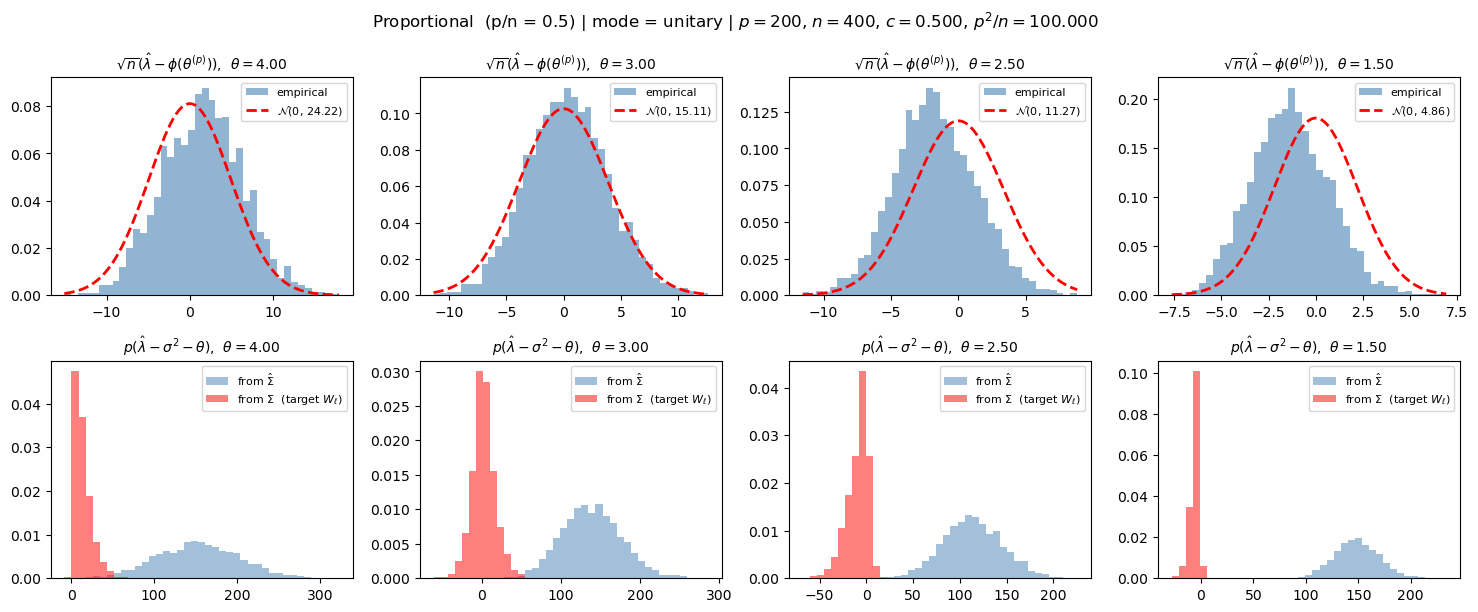


=== Proportional  (p/n = 0.5) | mode=orthogonal | p=200, n=400 ===


orthogonal   p= 200  n=  400: 100%|██████████| 3000/3000 [02:57<00:00, 16.93it/s]


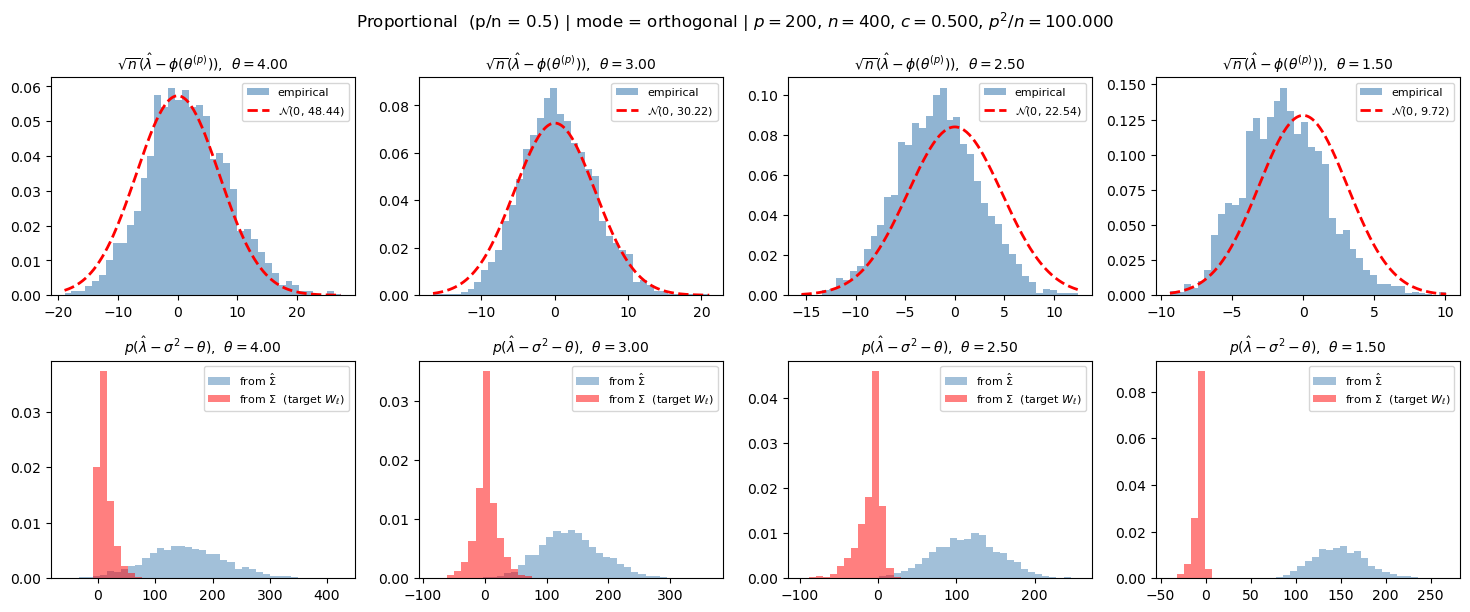


=== Sub-proportional  (p^2/n = 0.1) | mode=unitary | p=20, n=4000 ===


unitary      p=  20  n= 4000: 100%|██████████| 3000/3000 [00:14<00:00, 209.46it/s]


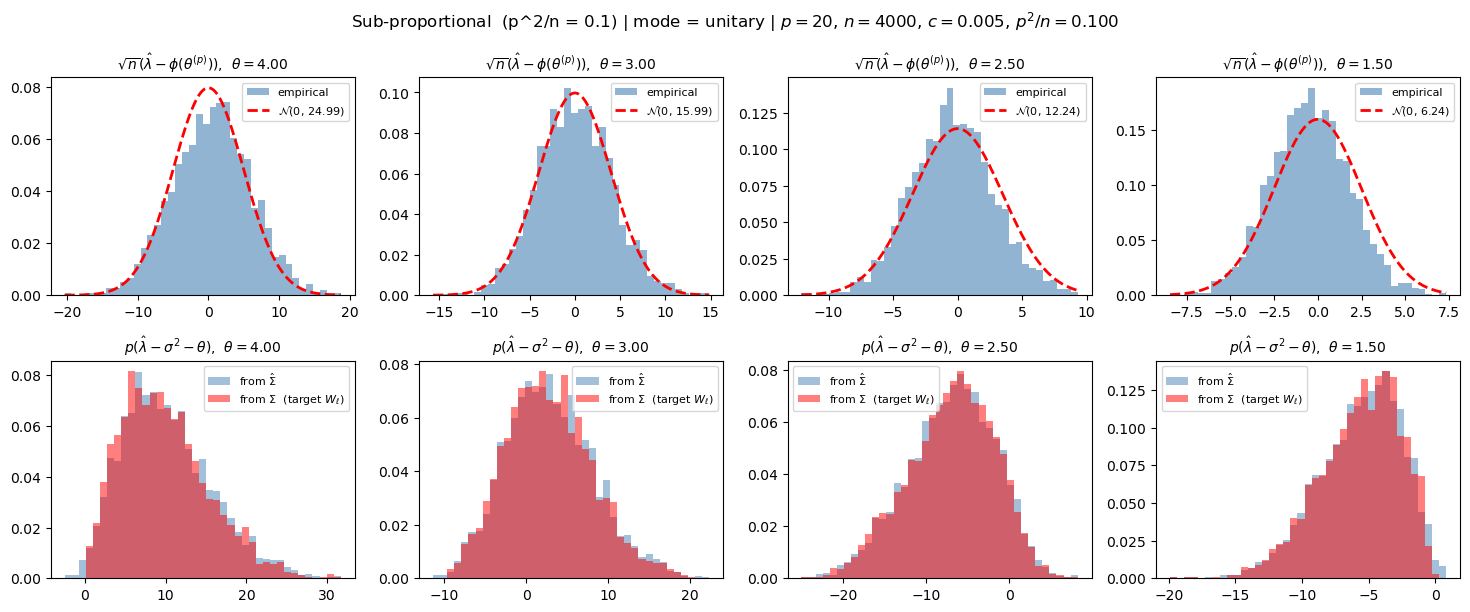


=== Sub-proportional  (p^2/n = 0.1) | mode=orthogonal | p=20, n=4000 ===


orthogonal   p=  20  n= 4000: 100%|██████████| 3000/3000 [00:06<00:00, 493.70it/s]


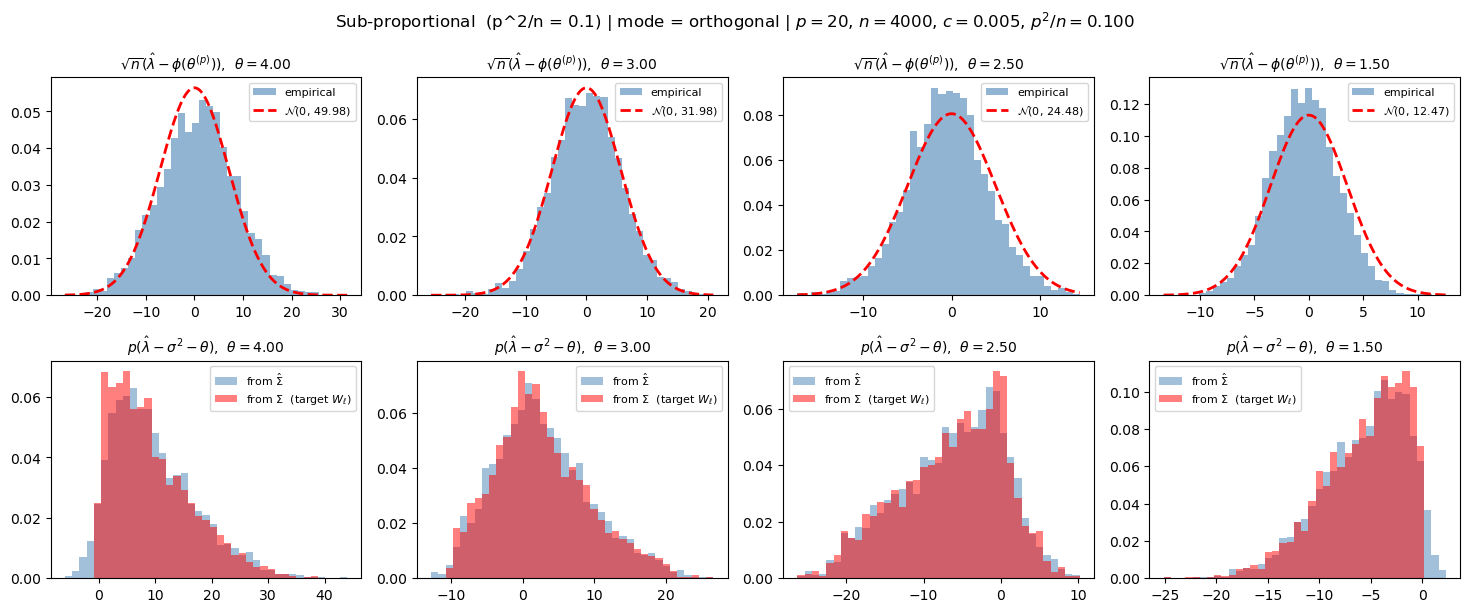


=== Intermediate  (p/n=0.1, p^2/n=5) | mode=unitary | p=50, n=500 ===


unitary      p=  50  n=  500: 100%|██████████| 3000/3000 [00:10<00:00, 296.54it/s]


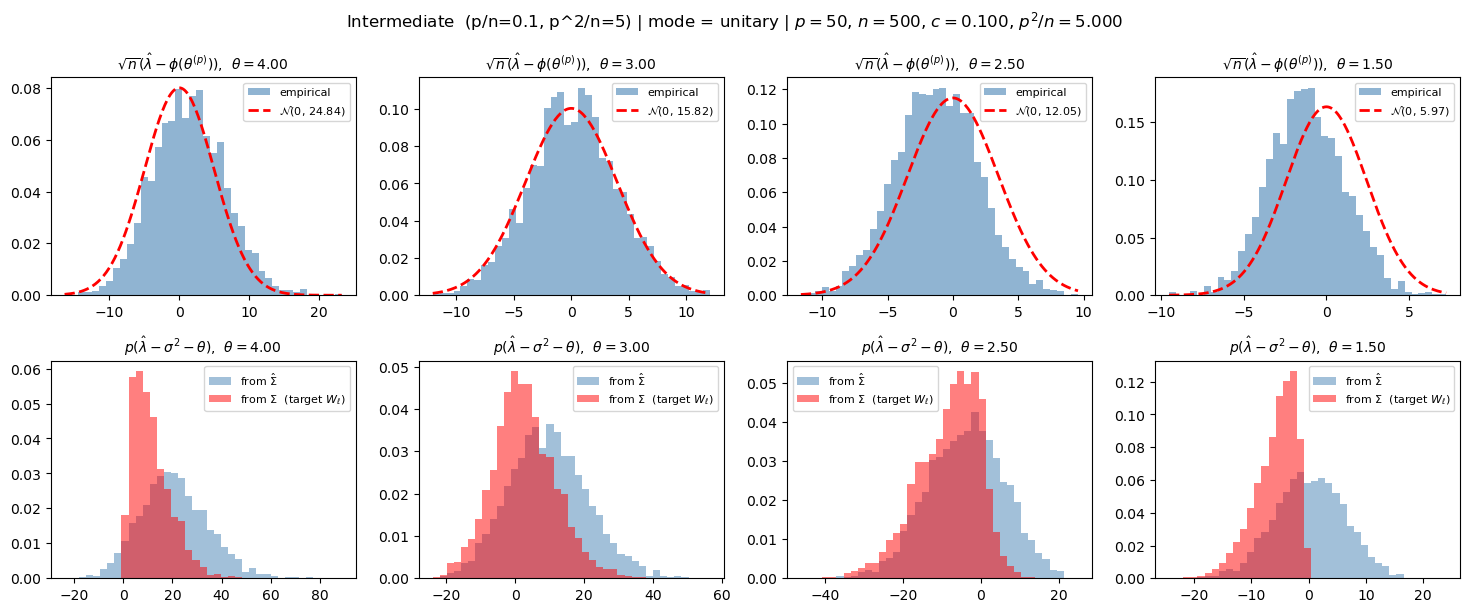


=== Intermediate  (p/n=0.1, p^2/n=5) | mode=orthogonal | p=50, n=500 ===


orthogonal   p=  50  n=  500: 100%|██████████| 3000/3000 [00:06<00:00, 476.07it/s]


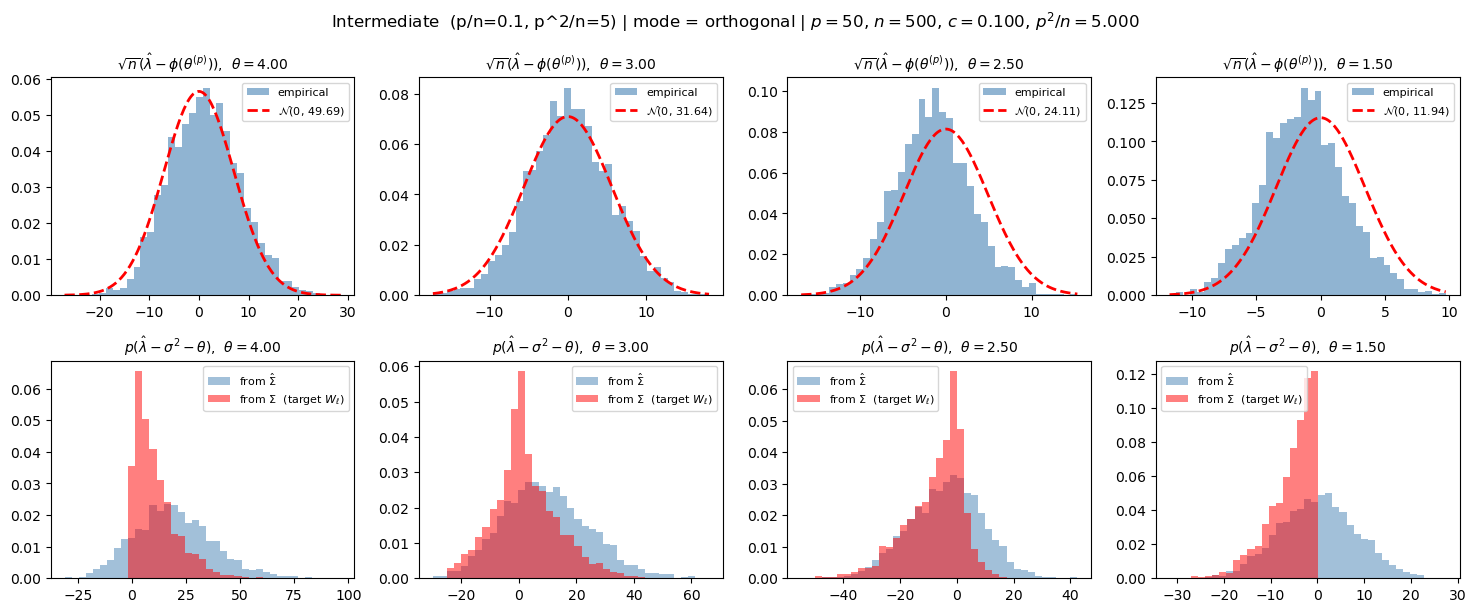

In [8]:
# -----------------------------------------------------------------------------
# Run
# -----------------------------------------------------------------------------
alphas    = np.array([4.0, 2.5])
betas     = np.array([3.0, 1.5])
sigma2    = 1.0
theta_vec = np.sort(np.concatenate([alphas, betas]))[::-1]    # decreasing
print(f"Spikes (sorted decreasingly): {theta_vec}")

configs = [
    ('Proportional  (p/n = 0.5)',          200,  400),
    ('Sub-proportional  (p^2/n = 0.1)',     20, 4000),
    ('Intermediate  (p/n=0.1, p^2/n=5)',    50,  500),
]

for (regime, p, n) in configs:
    for mode in ['unitary', 'orthogonal']:
        rng = np.random.default_rng(SEED)
        print(f"\n=== {regime} | mode={mode} | p={p}, n={n} ===")
        pop_eigs, sample_eigs = run_experiment(p, n, alphas, betas, sigma2, N_SIM, mode, rng)
        title = f'{regime} | mode = {mode} | $p={p}$, $n={n}$, $c={p/n:.3f}$, $p^2/n={p**2/n:.3f}$'
        plot_comparison(pop_eigs, sample_eigs, theta_vec, sigma2, p, n, mode, title)
        plt.show()